## Carregando os dados

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# importando bibliotecas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pandas.plotting import scatter_matrix

#importando o arquivo
df = pd.read_csv('/content/drive/My Drive/FATEC/PI5/StressLevelDataset.csv', sep=',')
df.head()


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


In [ ]:
# Quantidade de linhas e colunas
print("Dimensões do dataset:", df.shape)

# Tipos dos dados e quantidade de valores preenchidos
df.info()

# Valores ausentes por coluna
print("\nValores ausentes por coluna:")
print(df.isna().sum())

# Linhas inteiramente iguais
print("\nQuantidade de linhas duplicadas:", df.duplicated().sum())

Dimensões do dataset: (1100, 21)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1100 entries, 0 to 1099
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype
---  ------                        --------------  -----
 0   anxiety_level                 1100 non-null   int64
 1   self_esteem                   1100 non-null   int64
 2   mental_health_history         1100 non-null   int64
 3   depression                    1100 non-null   int64
 4   headache                      1100 non-null   int64
 5   blood_pressure                1100 non-null   int64
 6   sleep_quality                 1100 non-null   int64
 7   breathing_problem             1100 non-null   int64
 8   noise_level                   1100 non-null   int64
 9   living_conditions             1100 non-null   int64
 10  safety                        1100 non-null   int64
 11  basic_needs                   1100 non-null   int64
 12  academic_performance          1100 non-null   int64
 13  

In [ ]:
# Estatísticas descritivas de todos os atributos
estatisticas = df.describe().T

# Selecionando e organizando as estatísticas
estatisticas = estatisticas[
    ['min', '25%', '50%', '75%', 'max', 'mean', 'std']
]

# Exibindo os resultados
display(estatisticas.round(2))

,min,25%,50%,75%,max,mean,std
anxiety_level,0.0,6.0,11.0,16.0,21.0,11.06,6.12
self_esteem,0.0,11.0,19.0,26.0,30.0,17.78,8.94
mental_health_history,0.0,0.0,0.0,1.0,1.0,0.49,0.50
depression,0.0,6.0,12.0,19.0,27.0,12.56,7.73
headache,0.0,1.0,3.0,3.0,5.0,2.51,1.41
blood_pressure,1.0,1.0,2.0,3.0,3.0,2.18,0.83
sleep_quality,0.0,1.0,2.5,4.0,5.0,2.66,1.55
breathing_problem,0.0,2.0,3.0,4.0,5.0,2.75,1.40
noise_level,0.0,2.0,3.0,3.0,5.0,2.65,1.33
living_conditions,0.0,2.0,2.0,3.0,5.0,2.52,1.12


In [ ]:
# Verificar valores únicos e suas frequências
for coluna in df.columns:
    print(f"\n{'='*50}")
    print(f"Atributo: {coluna}")
    print(f"Valores possíveis: {sorted(df[coluna].unique())}")
    print("\nFrequência:")
    print(df[coluna].value_counts().sort_index())


Atributo: anxiety_level
Valores possíveis: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21)]

Frequência:
anxiety_level
0     29
1     46
2     46
3     48
4     33
5     40
6     52
7     51
8     44
9     60
10    63
11    54
12    56
13    67
14    51
15    51
16    45
17    47
18    55
19    61
20    40
21    61
Name: count, dtype: int64

Atributo: self_esteem
Valores possíveis: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(11), np.int64(12), np.int64(13), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(19), np.int64(20), np.int64(21), np.int64(22), np.int64(23), np.int64(24), np.int64(25), np.int64(

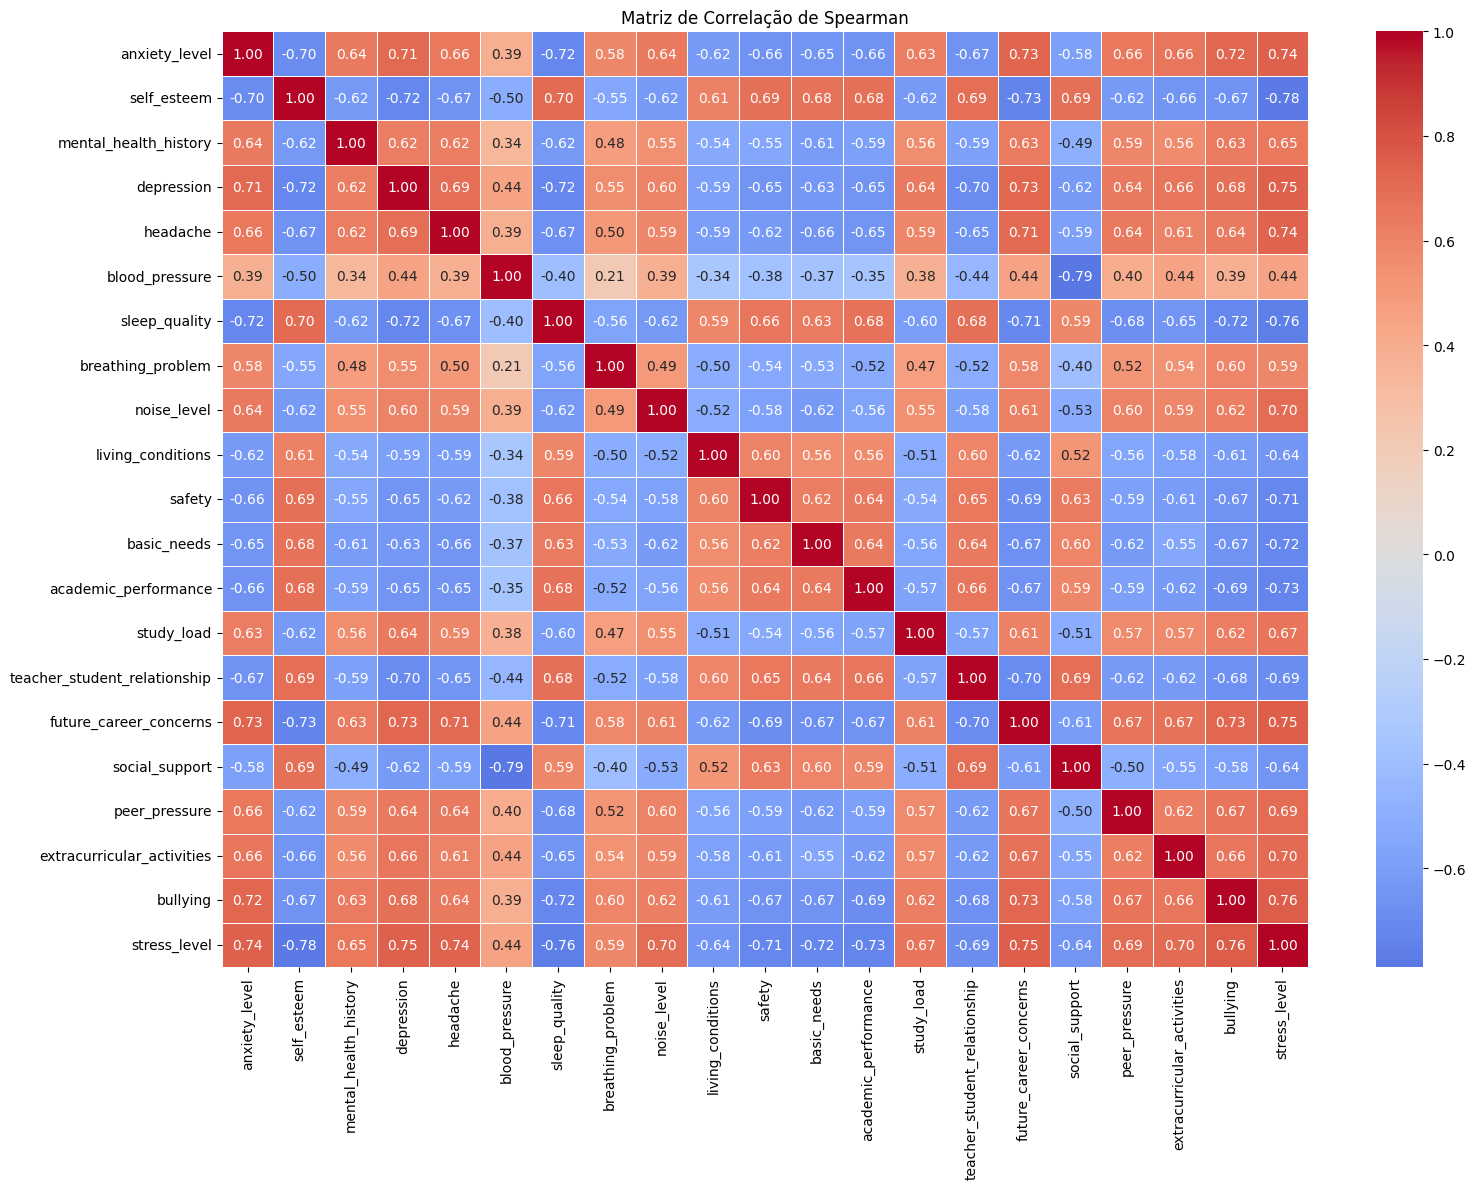


Correlação dos atributos com stress_level:


,Correlação
self_esteem,-0.779133
sleep_quality,-0.760959
bullying,0.760263
future_career_concerns,0.753981
depression,0.746773
anxiety_level,0.741869
headache,0.736590
academic_performance,-0.728272
basic_needs,-0.719037
safety,-0.714113


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Matriz de correlação
correlacao = df.corr(method='spearman')

# Visualização
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlacao,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    linewidths=0.5
)

plt.title('Matriz de Correlação de Spearman')
plt.tight_layout()
plt.show()

# Correlação dos atributos com a variável-alvo
correlacao_stress = correlacao['stress_level'].drop('stress_level')

correlacao_stress = correlacao_stress.reindex(
    correlacao_stress.abs().sort_values(ascending=False).index
)

print("\nCorrelação dos atributos com stress_level:")
display(correlacao_stress.to_frame('Correlação'))

## Pré-processamento: eliminação de atributos **com limitações de aplicabilidade**

In [ ]:
# Colunas escolhidas para retirada
colunas_remover = [
    'blood_pressure',
    'breathing_problem',
    'mental_health_history',
]

# Preservando o dataset original
df_reduzido = df.drop(columns=colunas_remover).copy()

print("Dataset original:", df.shape)
print("Dataset reduzido:", df_reduzido.shape)

display(df_reduzido.head())

Dataset original: (1100, 21)
Dataset reduzido: (1100, 18)


,anxiety_level,self_esteem,depression,headache,sleep_quality,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,11,2,2,2,3,3,2,3,2,3,3,2,3,3,2,1
1,15,8,15,5,1,3,1,2,2,1,4,1,5,1,4,5,5,2
2,12,18,14,2,2,2,2,3,2,2,3,3,2,2,3,2,2,1
3,16,12,15,4,1,4,2,2,2,2,4,1,4,1,4,4,5,2
4,16,28,7,2,5,3,2,4,3,4,3,1,2,1,5,0,5,1


## Pré-processamento: tratamento de atributos com valores ausentes

In [ ]:
# Identificando linhas com pelo menos um valor ausente
linhas_com_nan = df_reduzido.isna().any(axis=1)

# Exibindo essas linhas
display(df_reduzido.loc[linhas_com_nan])

,anxiety_level,self_esteem,depression,headache,sleep_quality,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level


## Pré-processamento: tratamento de dados inconsistentes ou redundantes

In [ ]:
# Identificando linhas iguais em todas as colunas da versão reduzida
df_duplicates = df_reduzido[
    df_reduzido.duplicated(keep=False)
]

# Exibindo o resultado
if len(df_duplicates) > 0:
    print('Linhas duplicadas:')
    display(df_duplicates)
else:
    print('Não existem linhas duplicadas.')

Não existem linhas duplicadas.


In [ ]:
# Entradas do modelo: todas as colunas, exceto o resultado
atributos = df_reduzido.columns.drop('stress_level').tolist()

# Contando quantas classes diferentes existem para cada conjunto de respostas
classes_por_resposta = (
    df_reduzido
    .groupby(atributos)['stress_level']
    .transform('nunique')
)

# Selecionando respostas iguais com classes diferentes
df_conflitos = df_reduzido[classes_por_resposta > 1]

if not df_conflitos.empty:
    print('Respostas iguais com classificações diferentes:')
    display(df_conflitos.sort_values(atributos))
else:
    print('Não existem respostas iguais com classificações diferentes.')


Não existem respostas iguais com classificações diferentes.


In [ ]:
# Apresentando as principais estatísticas da base reduzida
df_detalhes = df_reduzido.describe().T

display(df_detalhes)

,count,mean,std,min,25%,50%,75%,max
headache,1100.0,2.508182,1.409356,0.0,1.0,3.0,3.0,5.0
sleep_quality,1100.0,2.660000,1.548383,0.0,1.0,2.5,4.0,5.0
noise_level,1100.0,2.649091,1.328127,0.0,2.0,3.0,3.0,5.0
living_conditions,1100.0,2.518182,1.119208,0.0,2.0,2.0,3.0,5.0
safety,1100.0,2.737273,1.406171,0.0,2.0,2.0,4.0,5.0
basic_needs,1100.0,2.772727,1.433761,0.0,2.0,3.0,4.0,5.0
academic_performance,1100.0,2.772727,1.414594,0.0,2.0,2.0,4.0,5.0
study_load,1100.0,2.621818,1.315781,0.0,2.0,2.0,3.0,5.0
teacher_student_relationship,1100.0,2.648182,1.384579,0.0,2.0,2.0,4.0,5.0
future_career_concerns,1100.0,2.649091,1.529375,0.0,1.0,2.0,4.0,5.0


## Pré-processamento: detecção de *outliers*

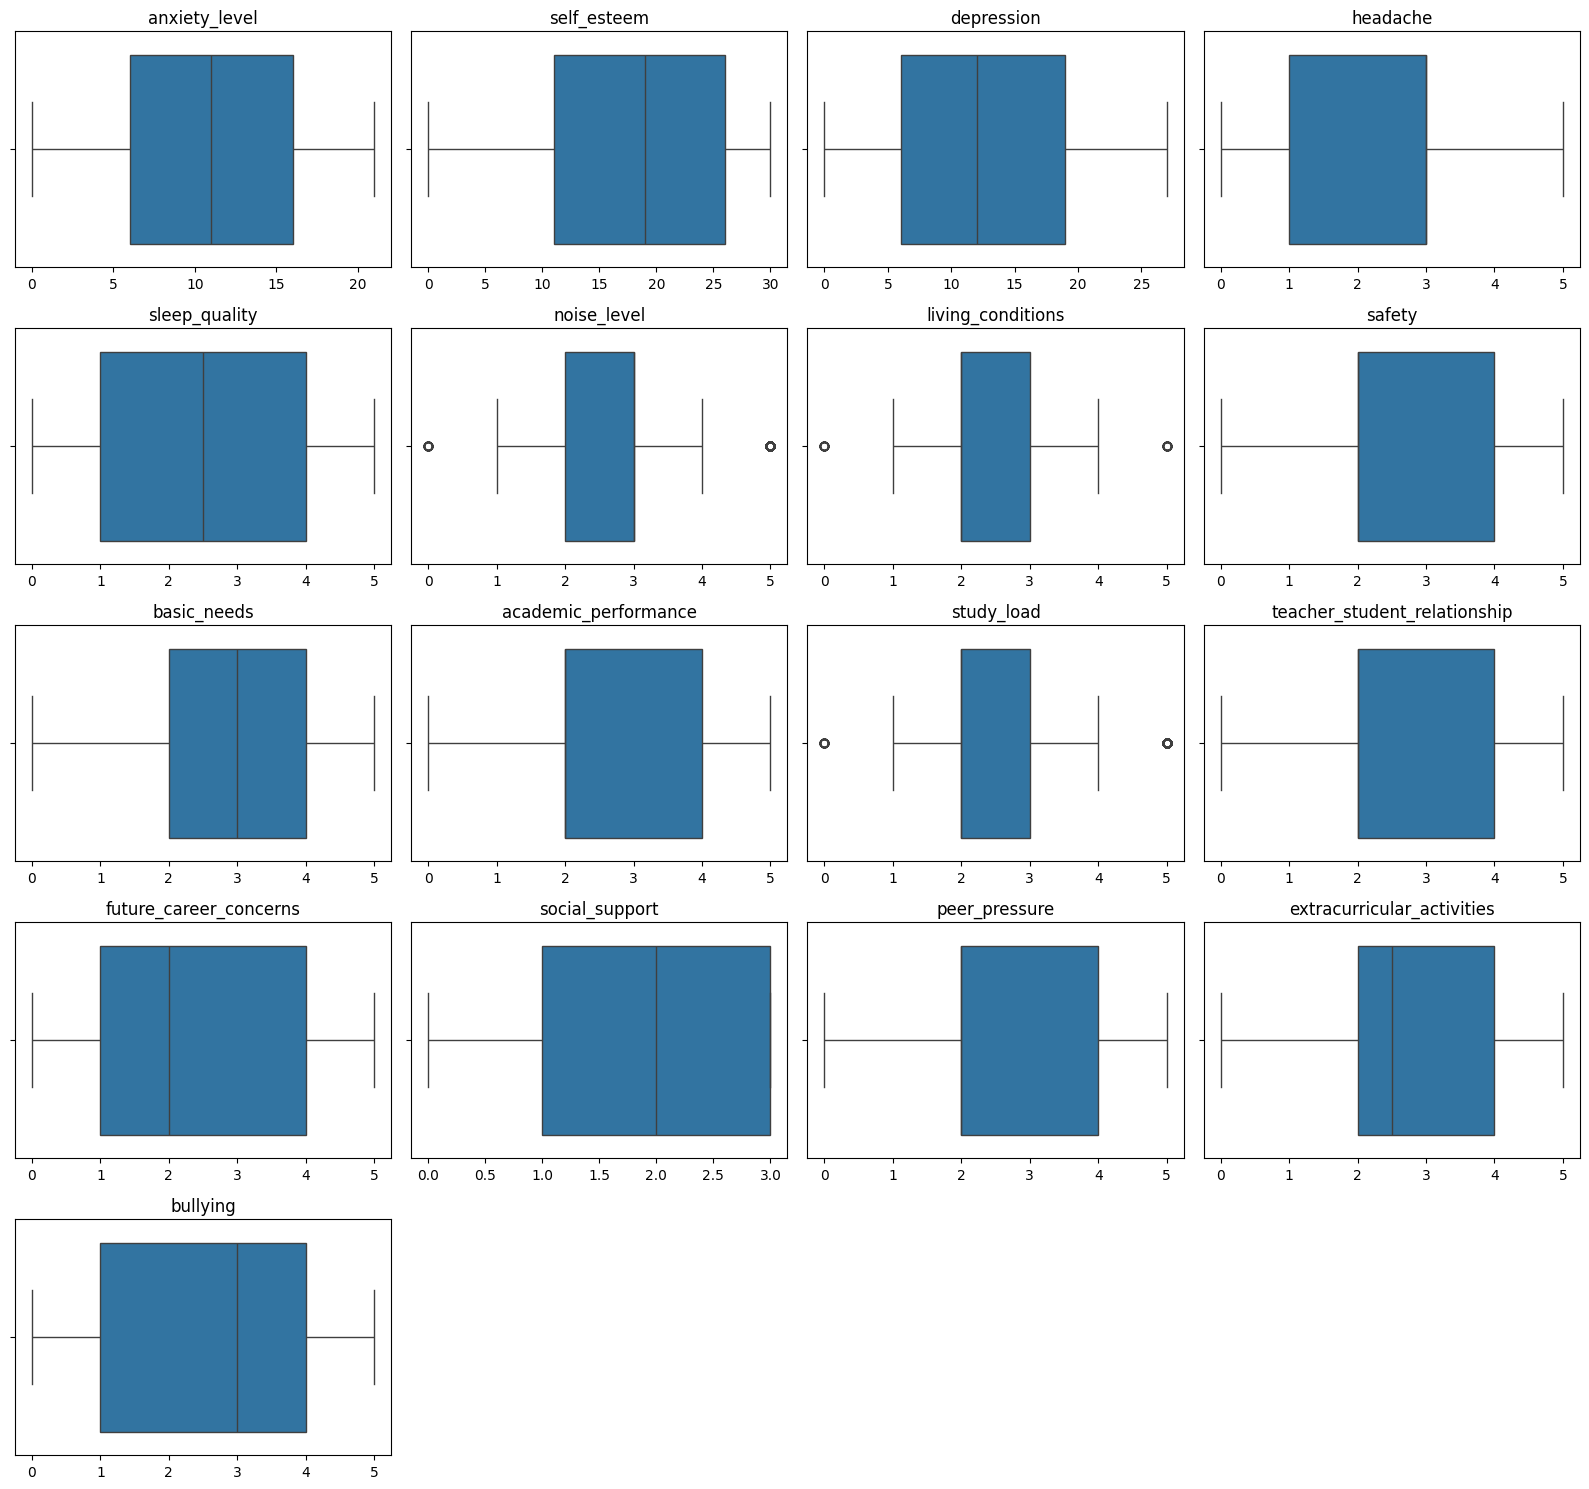

In [ ]:
# Entradas da versão reduzida, sem a classificação
atributos = df_reduzido.drop(columns=['stress_level'])

# Ajustado para 5x4 (20 subplots) para comportar as 17 colunas de atributos
fig, axes = plt.subplots(5, 4, figsize=(16, 15))
axes = axes.flatten()

for i, coluna in enumerate(atributos.columns):
    sns.boxplot(x=atributos[coluna], ax=axes[i])
    axes[i].set_title(coluna)
    axes[i].set_xlabel('')

# Ocultando os espaços excedentes sem gráficos
for j in range(len(atributos.columns), len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.show()

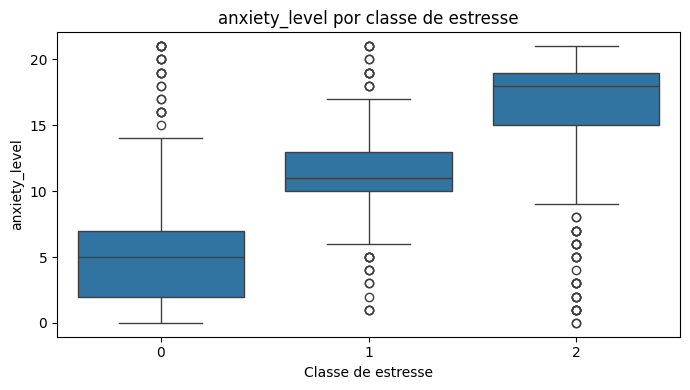

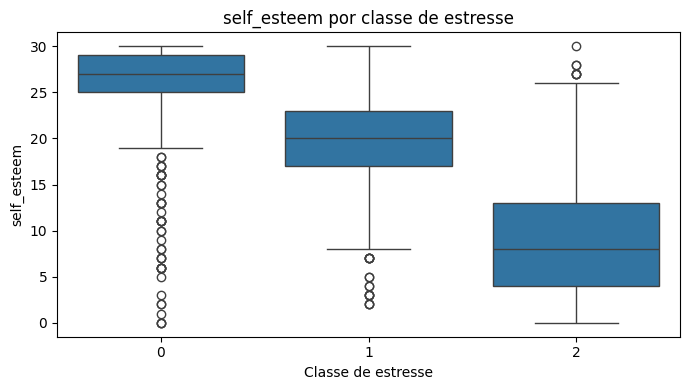

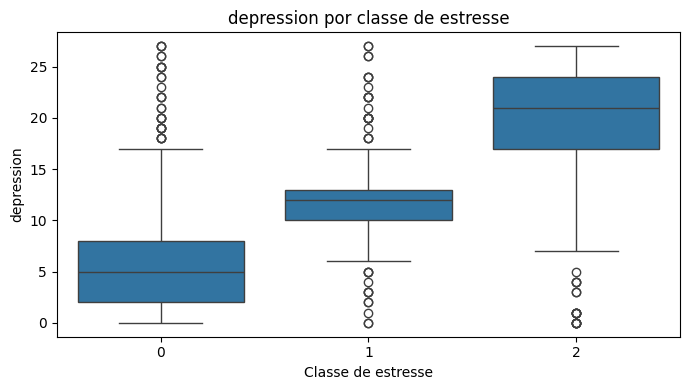

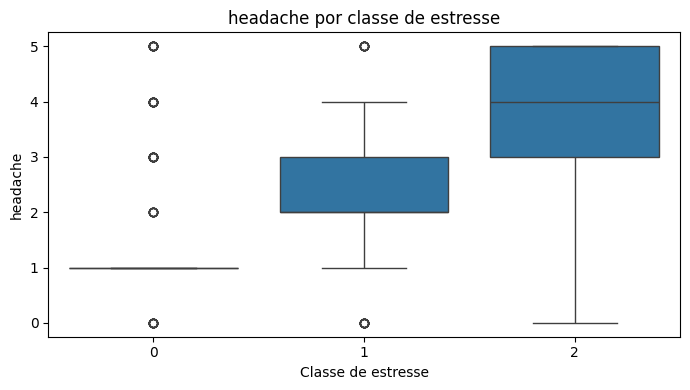

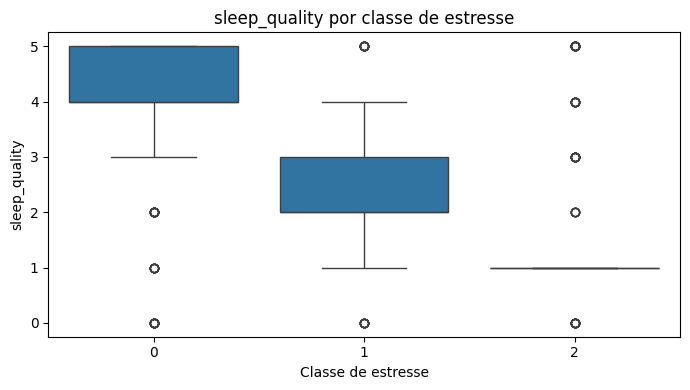

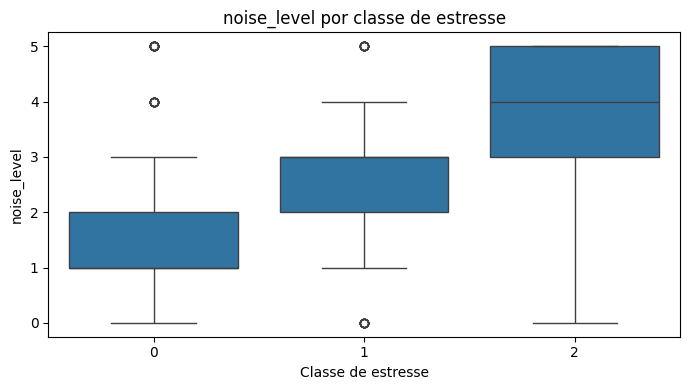

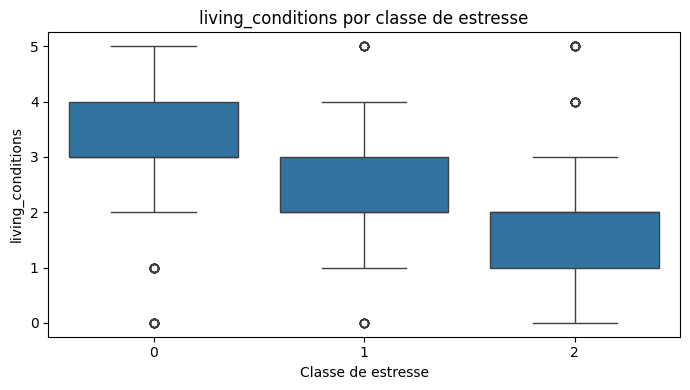

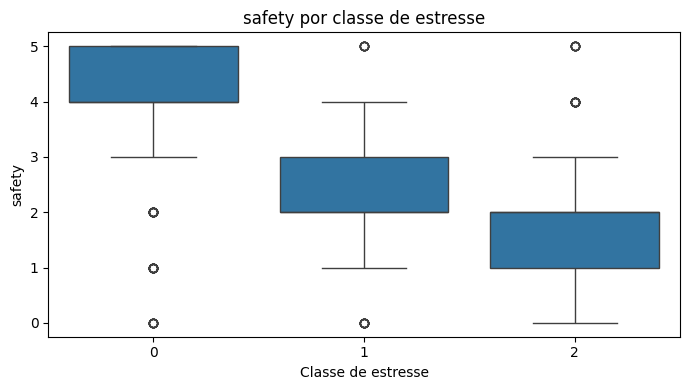

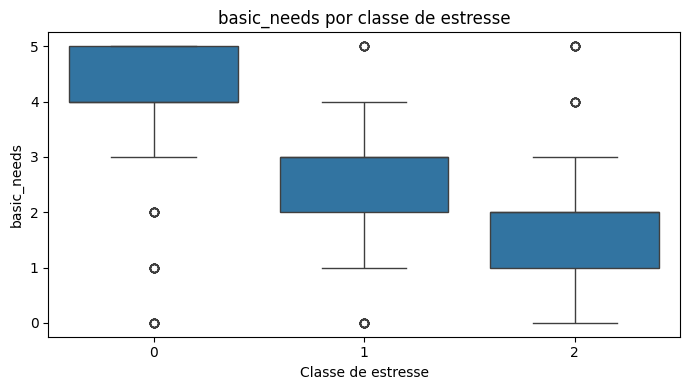

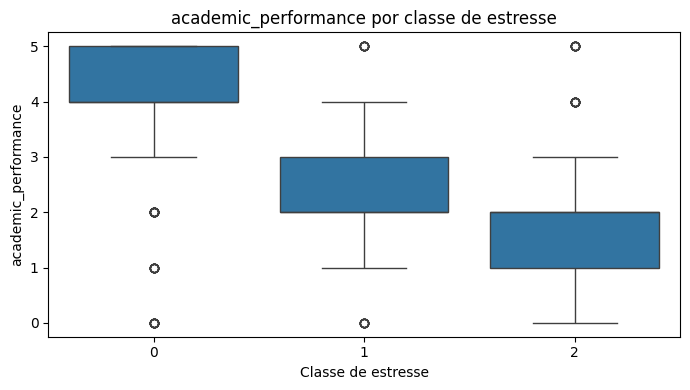

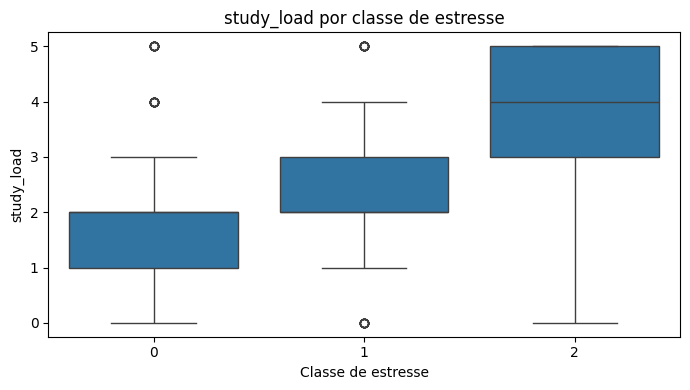

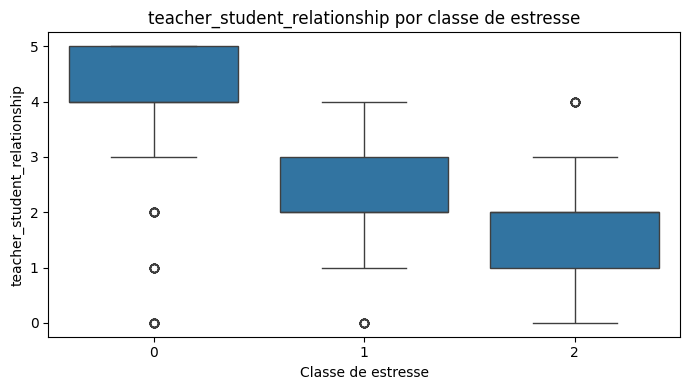

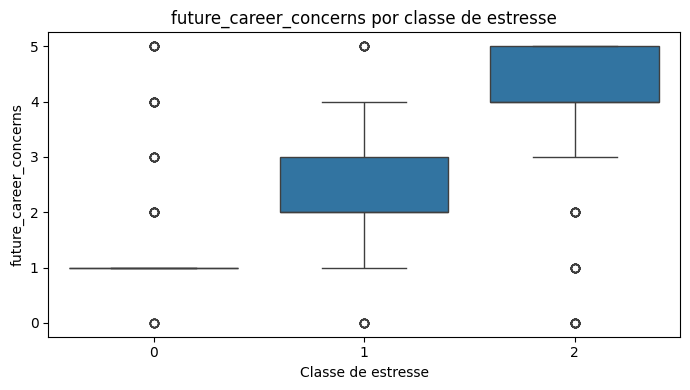

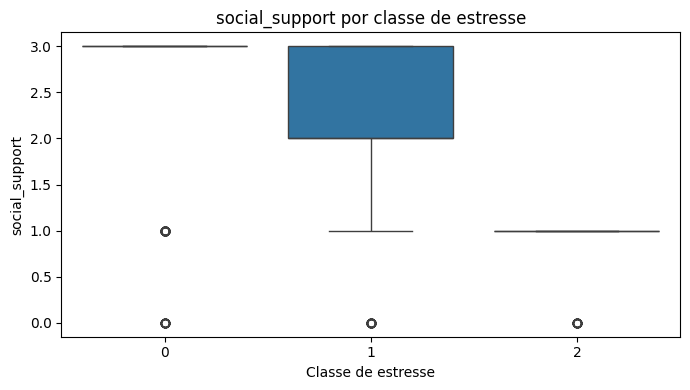

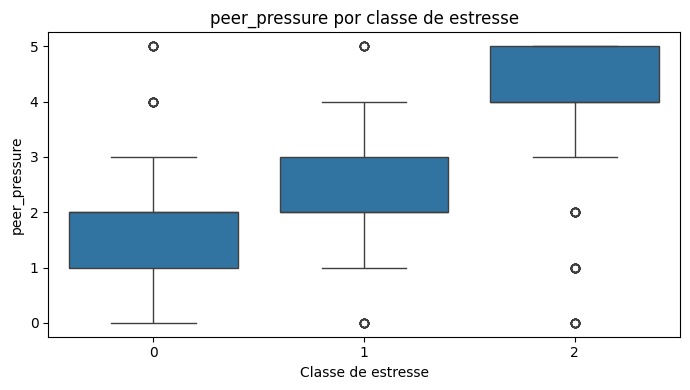

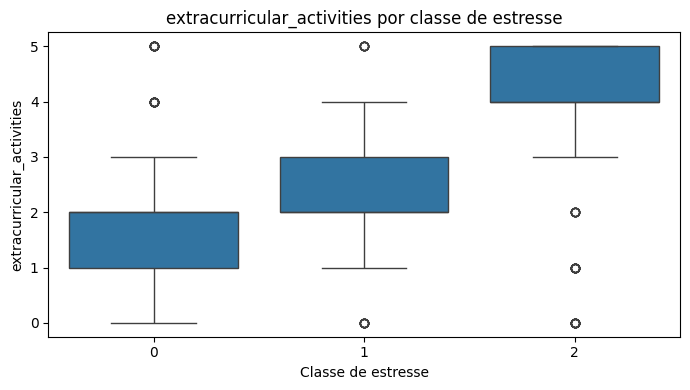

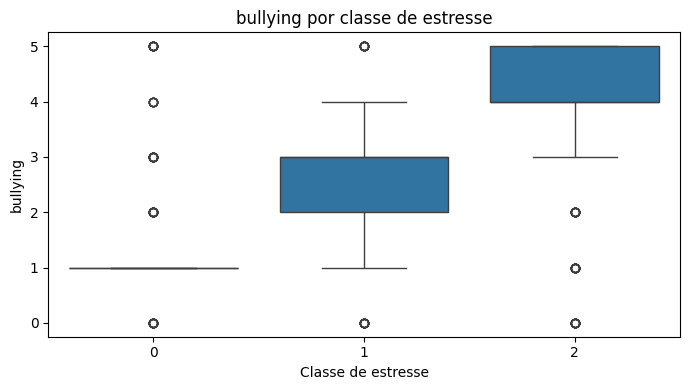

In [ ]:
# Selecionando as entradas, sem a coluna de resultado
atributos = df_reduzido.columns.drop('stress_level')

for atributo in atributos:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        x='stress_level',
        y=atributo,
        data=df_reduzido,
        whis=1.5
    )

    plt.title(f'{atributo} por classe de estresse')
    plt.xlabel('Classe de estresse')
    plt.ylabel(atributo)

    plt.tight_layout()
    plt.show()


In [ ]:
# Contando possíveis outliers por variável e classe,
# com o mesmo critério dos boxplots: 1,5 × IQR
resumo_outliers = []

for classe, grupo in df_reduzido.groupby('stress_level'):
    for atributo in df_reduzido.columns.drop('stress_level'):
        q1 = grupo[atributo].quantile(0.25)
        q3 = grupo[atributo].quantile(0.75)
        iqr = q3 - q1

        limite_inferior = q1 - 1.5 * iqr
        limite_superior = q3 + 1.5 * iqr

        fora = (
            (grupo[atributo] < limite_inferior) |
            (grupo[atributo] > limite_superior)
        )

        resumo_outliers.append({
            'variavel': atributo,
            'classe': classe,
            'limite_inferior': limite_inferior,
            'limite_superior': limite_superior,
            'quantidade_sinalizada': int(fora.sum())
        })

resumo_outliers = pd.DataFrame(resumo_outliers)

display(
    resumo_outliers[
        resumo_outliers['quantidade_sinalizada'] > 0
    ]
)

,variavel,classe,limite_inferior,limite_superior,quantidade_sinalizada
0,anxiety_level,0,-5.5,14.5,23
1,self_esteem,0,19.0,35.0,44
2,depression,0,-7.0,17.0,30
3,headache,0,1.0,1.0,61
4,sleep_quality,0,2.5,6.5,34
5,noise_level,0,-0.5,3.5,25
6,living_conditions,0,1.5,5.5,27
7,safety,0,2.5,6.5,38
8,basic_needs,0,2.5,6.5,34
9,academic_performance,0,2.5,6.5,36


## Pré-processamento: distribuição das classes

,count
stress_level,
0,373
1,358
2,369


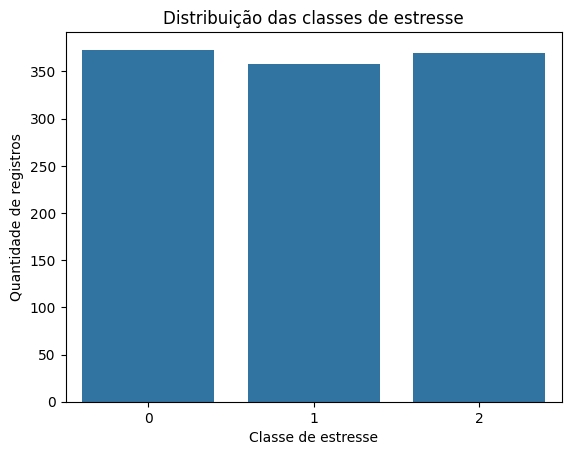

In [ ]:
# Quantidade de registros por classe
display(df_reduzido['stress_level'].value_counts().sort_index())

# Gráfico de barras com a frequência de cada classe
sns.countplot(
    x='stress_level',
    data=df_reduzido,
    order=[0, 1, 2]
)

plt.title('Distribuição das classes de estresse')
plt.xlabel('Classe de estresse')
plt.ylabel('Quantidade de registros')

plt.show()

## Pré-processamento: correlação entre os atributos

,anxiety_level,self_esteem,depression,headache,sleep_quality,noise_level,living_conditions,safety,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying
anxiety_level,1.00,-0.70,0.71,0.66,-0.72,0.64,-0.62,-0.66,-0.65,-0.66,0.63,-0.67,0.73,-0.58,0.66,0.66,0.72
self_esteem,-0.70,1.00,-0.72,-0.67,0.70,-0.62,0.61,0.69,0.68,0.68,-0.62,0.69,-0.73,0.69,-0.62,-0.66,-0.67
depression,0.71,-0.72,1.00,0.69,-0.72,0.60,-0.59,-0.65,-0.63,-0.65,0.64,-0.70,0.73,-0.62,0.64,0.66,0.68
headache,0.66,-0.67,0.69,1.00,-0.67,0.59,-0.59,-0.62,-0.66,-0.65,0.59,-0.65,0.71,-0.59,0.64,0.61,0.64
sleep_quality,-0.72,0.70,-0.72,-0.67,1.00,-0.62,0.59,0.66,0.63,0.68,-0.60,0.68,-0.71,0.59,-0.68,-0.65,-0.72
noise_level,0.64,-0.62,0.60,0.59,-0.62,1.00,-0.52,-0.58,-0.62,-0.56,0.55,-0.58,0.61,-0.53,0.60,0.59,0.62
living_conditions,-0.62,0.61,-0.59,-0.59,0.59,-0.52,1.00,0.60,0.56,0.56,-0.51,0.60,-0.62,0.52,-0.56,-0.58,-0.61
safety,-0.66,0.69,-0.65,-0.62,0.66,-0.58,0.60,1.00,0.62,0.64,-0.54,0.65,-0.69,0.63,-0.59,-0.61,-0.67
basic_needs,-0.65,0.68,-0.63,-0.66,0.63,-0.62,0.56,0.62,1.00,0.64,-0.56,0.64,-0.67,0.60,-0.62,-0.55,-0.67
academic_performance,-0.66,0.68,-0.65,-0.65,0.68,-0.56,0.56,0.64,0.64,1.00,-0.57,0.66,-0.67,0.59,-0.59,-0.62,-0.69


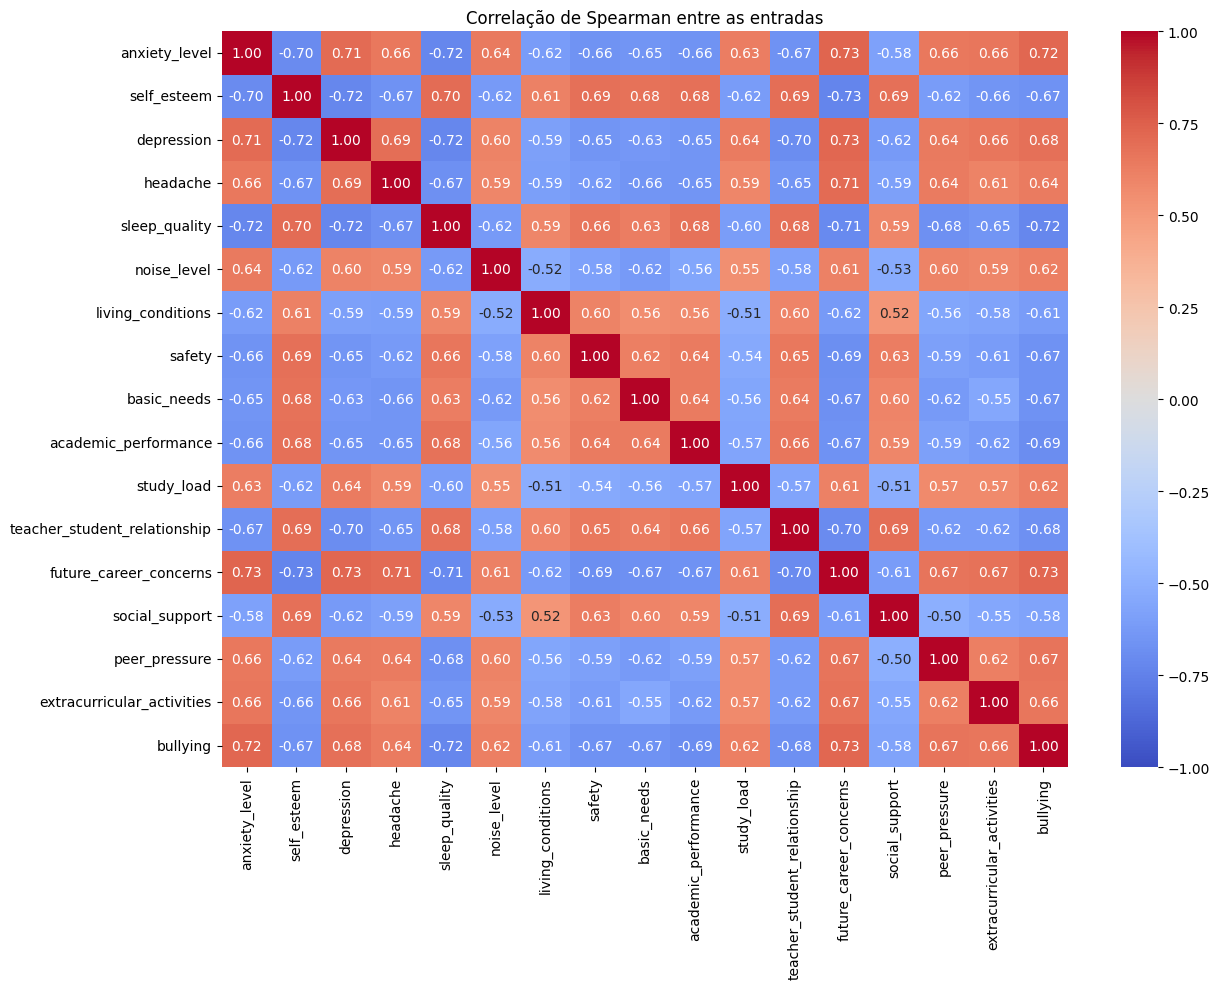

In [ ]:
# Selecionando somente as entradas
df_values = df_reduzido.drop(columns=['stress_level'])

# Matriz de correlação de Spearman
df_correlation = df_values.corr(method='spearman')

display(df_correlation.round(2))

# Visualizando a matriz
plt.figure(figsize=(13, 10))

sns.heatmap(
    df_correlation,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlação de Spearman entre as entradas')
plt.tight_layout()
plt.show()

In [ ]:
# Salvando o dataset com as três colunas removidas
df_reduzido.to_csv(
    '/content/drive/MyDrive/FATEC/PI5/StressLevelDataset_reduzido.csv',
    index=False
)